In [1]:
# STEP 1: Load the final corpus texts and check token totals

from pathlib import Path
import re
import pandas as pd

BASE_PATH = Path(
    "/Users/manalaltammami/Desktop/twain_child_corpus"
)

corpora = {
    "Twain": [
        "Tom_Sawyer_narrative.txt",
        "Huckleberry_Finn_narrative.txt",
        "Prince_and_the_Pauper_narrative.txt",
    ],
    "Child": [
        "Ragged_Dick_narrative.txt",
        "Little_Women_narrative.txt",
        "An_Old_Fashioned_Girl_narrative.txt",
        "Toby_Tyler_narrative.txt",
        "Five_Little_Peppers_narrative.txt",
        "Hoosier_Schoolboy_narrative.txt",
        "Little_Lord_Fauntleroy_narrative.txt",
        "The_Story_of_Patsy_narrative.txt",
    ],
    "Adult": [
        "Silas_Lapham_narrative.txt",
        "Ministers_Charge_narrative.txt",
        "Hazard_New_Fortunes_narrative.txt",
        "Portrait_of_a_Lady_narrative.txt",
        "Bostonians_narrative.txt",
        "Washington_Square_narrative.txt",
        "Pointed_Firs_narrative.txt",
        "Deephaven_narrative.txt",
        "Country_Doctor_narrative.txt",
        "Awakening_narrative.txt",
        "Graysons_narrative.txt",
        "McTeague_narrative.txt",
        "Octopus_narrative.txt",
        "Red_Badge_of_Courage_narrative.txt",
        "Maggie_narrative.txt",
        "Main_Travelled_Roads_narrative.txt",
        "Old_Creole_Days_narrative.txt",
        "Conjure_Woman_narrative.txt",
        "Looking_Backward_narrative.txt",
        "Theron_Ware_narrative.txt",
        "Sister_Carrie_narrative.txt",
        "Summer_narrative.txt",
        "Scarlet_Letter_narrative.txt",
        "Seven_Gables_narrative.txt",
        "Moby_Dick_narrative.txt",
        "Aspern_Papers_narrative.txt",
        "Bartleby_narrative.txt",
        "Benito_Cereno_narrative.txt",
    ],
}

EXPECTED_TOTALS = {
    "Twain": 248254,
    "Child": 561064,
    "Adult": 2636433,
}

TOKEN_PATTERN = re.compile(r"[a-z]+(?:['-][a-z]+)*")

def tokenize(text):
    return TOKEN_PATTERN.findall(
        text.lower().replace("’", "'")
    )

texts = {}
book_rows = []

all_files = [
    filename
    for filenames in corpora.values()
    for filename in filenames
]

assert len(all_files) == len(set(all_files)) == 39

for corpus, filenames in corpora.items():
    corpus_total = 0

    for filename in filenames:
        text = (BASE_PATH / filename).read_text(encoding="utf-8")
        texts[filename] = text

        total = len(tokenize(text))
        corpus_total += total

        book_rows.append({
            "Corpus": corpus,
            "File": filename,
            "Word tokens": total,
        })

    if corpus_total != EXPECTED_TOTALS[corpus]:
        raise ValueError(
            f"{corpus}: found {corpus_total:,} tokens; "
            f"expected {EXPECTED_TOTALS[corpus]:,}."
        )

    print(f"{corpus}: {corpus_total:,} tokens")

book_tokens = pd.DataFrame(book_rows)

print("\nAll 39 texts loaded in full.")


Twain: 248,254 tokens
Child: 561,064 tokens
Adult: 2,636,433 tokens

All 39 texts loaded in full.


In [4]:
# STEP 2: Extract possible a-prefixed forms for context review

from datetime import datetime

candidate_rows = []

for corpus, filenames in corpora.items():
    for filename in filenames:
        original = texts[filename]

        # Normalization preserves character positions.
        normalized = original.lower().replace("’", "'")

        for match in TOKEN_PATTERN.finditer(normalized):
            token = match.group()

            if not token.startswith("a-"):
                continue

            start, end = match.span()

            # Include a trailing apostrophe in the displayed form.
            if normalized[end:end + 1] == "'":
                end += 1

            candidate_rows.append({
                "Candidate ID": len(candidate_rows) + 1,
                "Corpus": corpus,
                "File": filename,
                "Start": start,
                "End": end,
                "Form": normalized[start:end],
                "Original wording": original[start:end],
                "Before": original[max(0, start - 400):start],
                "After": original[end:min(len(original), end + 400)],
                "Decision": "",
                "Reason": "",
            })

a_prefix_candidates = pd.DataFrame(candidate_rows)

if a_prefix_candidates.empty:
    raise ValueError("No a-prefixed candidates were found.")

output_folder = BASE_PATH / "a_prefixing_review"
output_folder.mkdir(exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
review_path = output_folder / f"a_prefix_candidates_{timestamp}.csv"

a_prefix_candidates.to_csv(
    review_path,
    index=False,
    encoding="utf-8",
    mode="x",
)

print("Candidate occurrences:", len(a_prefix_candidates))
print("Distinct forms:", a_prefix_candidates["Form"].nunique())

print("\nCandidates by corpus:")
print(a_prefix_candidates.groupby("Corpus").size().to_string())

print("\nMost frequent candidate forms:")
print(a_prefix_candidates["Form"].value_counts().head(25).to_string())

print("\nSaved to:", review_path)
print("\nThese are candidates—not verified verbal a-prefixing counts.")

Candidate occurrences: 574
Distinct forms: 287

Candidates by corpus:
Corpus
Adult    270
Child     62
Twain    242

Most frequent candidate forms:
Form
a-goin'        54
a-going        44
a-comin'       16
a-coming        8
a-sayin'        8
a-gittin'       8
a-standing      7
a-holt          7
a-lookin'       7
a-thinkin'      7
a-rabs          6
a-gwyne         6
a-talkin'       6
a-runnin'       5
a-cryin'        5
a-standin'      5
a-doin'         5
a-whaling       5
a-swimming      4
a-fishing       4
a-begging       4
a-plenty        4
a-visiting      4
a-hollerin'     4
a-waitin'       4

Saved to: /Users/manalaltammami/Desktop/twain_child_corpus/a_prefixing_review/a_prefix_candidates_20261103_220817_386340.csv

These are candidates—not verified verbal a-prefixing counts.


In [6]:
from pathlib import Path
import pandas as pd

review_path = Path.home() / "Downloads" / "a_prefix_REVIEWED.csv"

if not review_path.is_file():
    raise FileNotFoundError(
        "Save the reviewed CSV in Downloads as a_prefix_REVIEWED.csv."
    )

a_prefix_review = pd.read_csv(review_path)

if a_prefix_review["Decision"].isna().any():
    raise ValueError("Some review decisions are blank.")

print("Review decisions:")
print(a_prefix_review["Decision"].value_counts())

a_prefix_included = a_prefix_review.loc[
    a_prefix_review["Decision"].eq("Include")
].copy()

print(f"\nRetained occurrences: {len(a_prefix_included):,}")

Review decisions:
Decision
Include    487
Exclude     87
Name: count, dtype: int64

Retained occurrences: 487


In [9]:
# Count retained a-prefixing occurrences per book
match_counts = (
    a_prefix_included
    .groupby(["Corpus", "File"])
    .size()
    .rename("A-prefixing count")
    .reset_index()
)

# Keep every book, including those with zero matches
a_prefix_by_book = book_tokens.merge(
    match_counts,
    on=["Corpus", "File"],
    how="left",
    validate="one_to_one"
)

a_prefix_by_book["A-prefixing count"] = (
    a_prefix_by_book["A-prefixing count"]
    .fillna(0)
    .astype(int)
)

a_prefix_by_book["Per 10,000"] = (
    a_prefix_by_book["A-prefixing count"]
    / a_prefix_by_book["Word tokens"]
    * 10000
)

# Calculate pooled corpus rates
a_prefix_by_corpus = (
    a_prefix_by_book
    .groupby("Corpus", sort=False)[
        ["Word tokens", "A-prefixing count"]
    ]
    .sum()
)

a_prefix_by_corpus["Per 10,000"] = (
    a_prefix_by_corpus["A-prefixing count"]
    / a_prefix_by_corpus["Word tokens"]
    * 10000
)

assert a_prefix_by_book["A-prefixing count"].sum() == len(
    a_prefix_included
)

print("PER BOOK")
print(a_prefix_by_book.round(3).to_string(index=False))

print("\nPOOLED CORPORA")
print(a_prefix_by_corpus.round(3).to_string())

PER BOOK
Corpus                                 File  Word tokens  A-prefixing count  Per 10,000
 Twain             Tom_Sawyer_narrative.txt        70518                 21       2.978
 Twain       Huckleberry_Finn_narrative.txt       110729                190      17.159
 Twain  Prince_and_the_Pauper_narrative.txt        67007                  0       0.000
 Child            Ragged_Dick_narrative.txt        47722                  3       0.629
 Child           Little_Women_narrative.txt       185825                  5       0.269
 Child  An_Old_Fashioned_Girl_narrative.txt       101818                  1       0.098
 Child             Toby_Tyler_narrative.txt        50233                  0       0.000
 Child    Five_Little_Peppers_narrative.txt        69400                 27       3.890
 Child      Hoosier_Schoolboy_narrative.txt        36080                  3       0.831
 Child Little_Lord_Fauntleroy_narrative.txt        58627                  3       0.512
 Child     The_Story_of

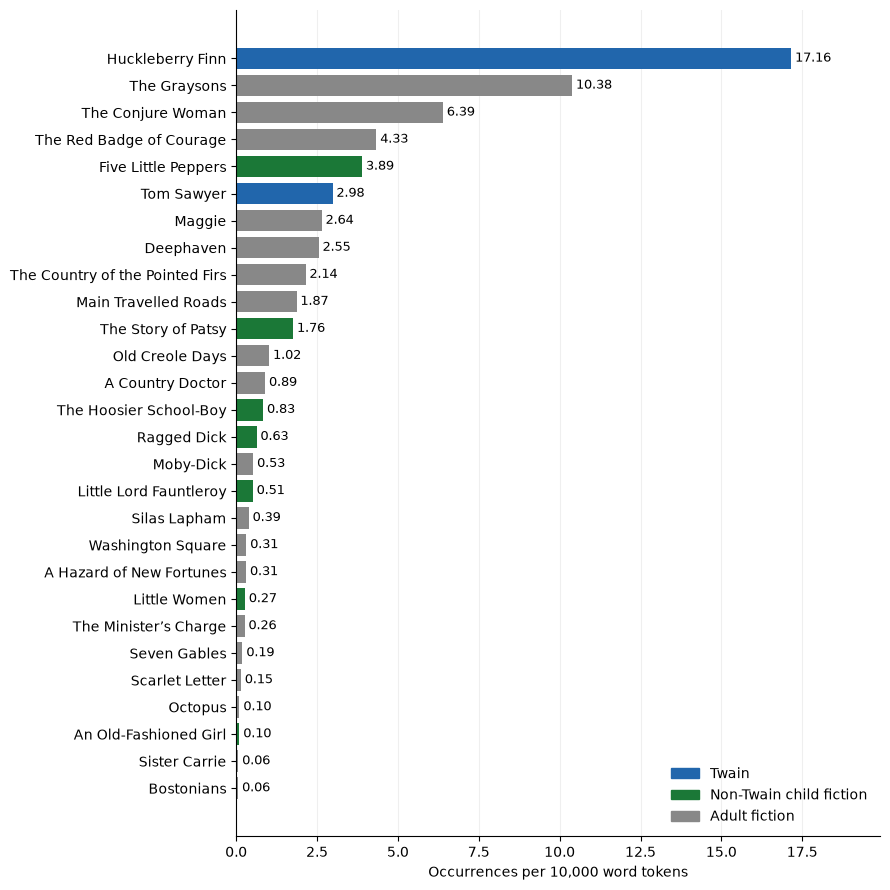

Figures saved in: /Users/manalaltammami/Desktop/twain_child_corpus/figures


In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from datetime import datetime

# Use the results already calculated in this notebook.
plot_data = a_prefix_by_book.loc[
    a_prefix_by_book["A-prefixing count"] > 0
].copy()

plot_data["Title"] = (
    plot_data["File"]
    .str.replace("_narrative.txt", "", regex=False)
    .str.replace("_", " ", regex=False)
)

plot_data["Title"] = plot_data["Title"].replace({
    "Ministers Charge": "The Minister’s Charge",
    "Hazard New Fortunes": "A Hazard of New Fortunes",
    "Pointed Firs": "The Country of the Pointed Firs",
    "Country Doctor": "A Country Doctor",
    "Graysons": "The Graysons",
    "Conjure Woman": "The Conjure Woman",
    "Red Badge of Courage": "The Red Badge of Courage",
    "An Old Fashioned Girl": "An Old-Fashioned Girl",
    "Hoosier Schoolboy": "The Hoosier School-Boy",
    "Moby Dick": "Moby-Dick",
})

plot_data = plot_data.sort_values("Per 10,000")

colors = {
    "Twain": "#2166AC",
    "Child": "#1B7837",
    "Adult": "#888888",
}

fig, ax = plt.subplots(figsize=(9, 9))

ax.barh(
    plot_data["Title"],
    plot_data["Per 10,000"],
    color=plot_data["Corpus"].map(colors)
)

for position, rate in enumerate(plot_data["Per 10,000"]):
    ax.text(
        rate + 0.12,
        position,
        f"{rate:.2f}",
        va="center",
        fontsize=9
    )

ax.set_xlabel("Occurrences per 10,000 word tokens")
ax.set_ylabel("")
ax.set_xlim(0, plot_data["Per 10,000"].max() * 1.16)

ax.legend(
    handles=[
        Patch(color=colors["Twain"], label="Twain"),
        Patch(color=colors["Child"], label="Non-Twain child fiction"),
        Patch(color=colors["Adult"], label="Adult fiction"),
    ],
    loc="lower right",
    frameon=False
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

# Timestamp prevents overwriting an existing figure.
figure_folder = Path(
    "/Users/manalaltammami/Desktop/twain_child_corpus/figures"
)
figure_folder.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
filename = f"Figure_3_a_prefixing_{timestamp}"

fig.savefig(
    figure_folder / f"{filename}.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    figure_folder / f"{filename}.pdf",
    bbox_inches="tight"
)

plt.show()

print(f"Figures saved in: {figure_folder}")

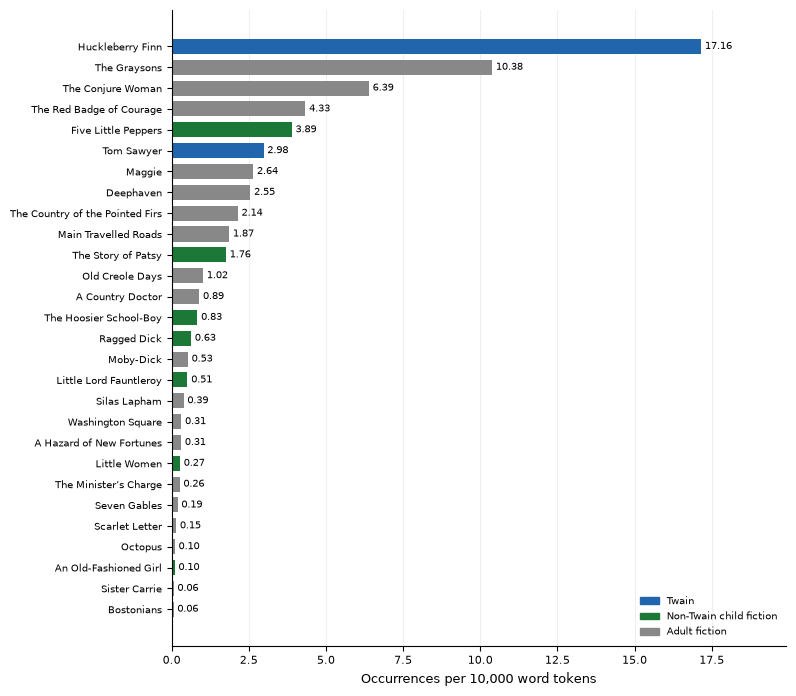

Figures saved in: /Users/manalaltammami/Desktop/twain_child_corpus/figures


In [16]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from datetime import datetime

# Use the results already calculated in this notebook.
plot_data = a_prefix_by_book.loc[
    a_prefix_by_book["A-prefixing count"] > 0
].copy()

plot_data["Title"] = (
    plot_data["File"]
    .str.replace("_narrative.txt", "", regex=False)
    .str.replace("_", " ", regex=False)
)

plot_data["Title"] = plot_data["Title"].replace({
    "Ministers Charge": "The Minister’s Charge",
    "Hazard New Fortunes": "A Hazard of New Fortunes",
    "Pointed Firs": "The Country of the Pointed Firs",
    "Country Doctor": "A Country Doctor",
    "Graysons": "The Graysons",
    "Conjure Woman": "The Conjure Woman",
    "Red Badge of Courage": "The Red Badge of Courage",
    "An Old Fashioned Girl": "An Old-Fashioned Girl",
    "Hoosier Schoolboy": "The Hoosier School-Boy",
    "Moby Dick": "Moby-Dick",
})

plot_data = plot_data.sort_values("Per 10,000")

colors = {
    "Twain": "#2166AC",
    "Child": "#1B7837",
    "Adult": "#888888",
}

# Smaller figure: previously (9, 9)
fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(
    plot_data["Title"],
    plot_data["Per 10,000"],
    color=plot_data["Corpus"].map(colors),
    height=0.72
)

# Smaller numerical labels
for position, rate in enumerate(plot_data["Per 10,000"]):
    ax.text(
        rate + 0.12,
        position,
        f"{rate:.2f}",
        va="center",
        fontsize=7
    )

# Reduce font sizes for compact layout
ax.tick_params(axis="y", labelsize=7)
ax.tick_params(axis="x", labelsize=8)

ax.set_xlabel(
    "Occurrences per 10,000 word tokens",
    fontsize=9
)
ax.set_ylabel("")
ax.set_xlim(0, plot_data["Per 10,000"].max() * 1.16)

ax.legend(
    handles=[
        Patch(color=colors["Twain"], label="Twain"),
        Patch(color=colors["Child"], label="Non-Twain child fiction"),
        Patch(color=colors["Adult"], label="Adult fiction"),
    ],
    loc="lower right",
    fontsize=7,
    frameon=False
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

# Save without overwriting previous figures
figure_folder = Path(
    "/Users/manalaltammami/Desktop/twain_child_corpus/figures"
)
figure_folder.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
filename = f"Figure_3_a_prefixing_{timestamp}"

fig.savefig(
    figure_folder / f"{filename}.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure_folder / f"{filename}.pdf",
    bbox_inches="tight"
)

plt.show()

print(f"Figures saved in: {figure_folder}")


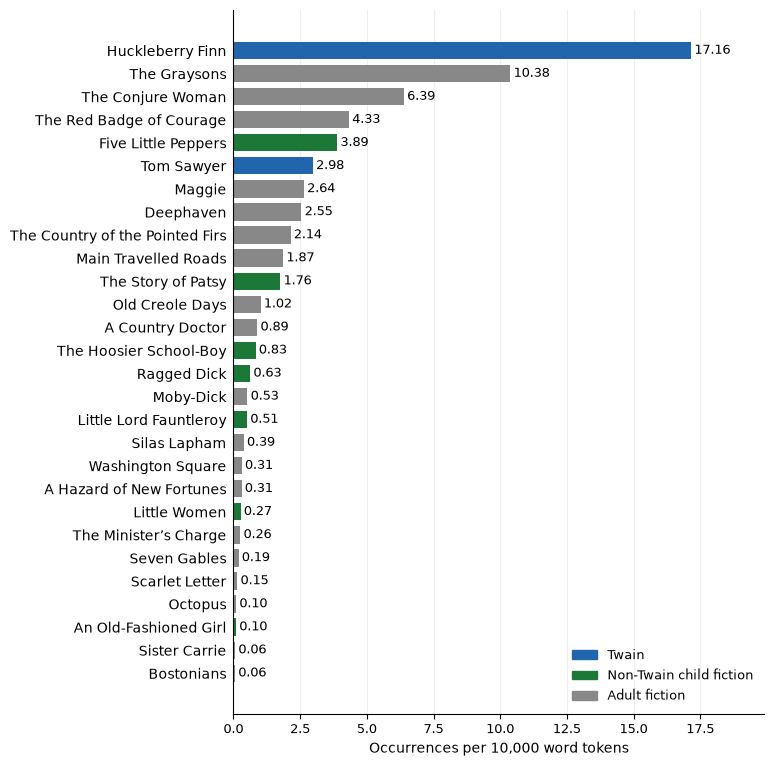

Figures saved in: /Users/manalaltammami/Desktop/twain_child_corpus/figures
Filename: Figure_3_a_prefixing_20261103_221645_307993


In [18]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from datetime import datetime

# Use the results already calculated in this notebook.
plot_data = a_prefix_by_book.loc[
    a_prefix_by_book["A-prefixing count"] > 0
].copy()

# Prepare novel titles
plot_data["Title"] = (
    plot_data["File"]
    .str.replace("_narrative.txt", "", regex=False)
    .str.replace("_", " ", regex=False)
)

# Correct and standardize novel titles
plot_data["Title"] = plot_data["Title"].replace({
    "Ministers Charge": "The Minister’s Charge",
    "Hazard New Fortunes": "A Hazard of New Fortunes",
    "Pointed Firs": "The Country of the Pointed Firs",
    "Country Doctor": "A Country Doctor",
    "Graysons": "The Graysons",
    "Conjure Woman": "The Conjure Woman",
    "Red Badge of Courage": "The Red Badge of Courage",
    "An Old Fashioned Girl": "An Old-Fashioned Girl",
    "Hoosier Schoolboy": "The Hoosier School-Boy",
    "Moby Dick": "Moby-Dick",
})

# Sort by frequency
plot_data = plot_data.sort_values("Per 10,000")

# Corpus colors
colors = {
    "Twain": "#2166AC",
    "Child": "#1B7837",
    "Adult": "#888888",
}

# Figure dimensions: compact but readable
fig, ax = plt.subplots(figsize=(9, 8))

# Horizontal bar chart
ax.barh(
    plot_data["Title"],
    plot_data["Per 10,000"],
    color=plot_data["Corpus"].map(colors),
    height=0.75
)

# Display frequency values beside each bar
for position, rate in enumerate(plot_data["Per 10,000"]):
    ax.text(
        rate + 0.12,
        position,
        f"{rate:.2f}",
        va="center",
        fontsize=9
    )

# Readable novel titles and axis labels
ax.tick_params(
    axis="y",
    labelsize=10,
    length=0,
    pad=5
)

ax.tick_params(
    axis="x",
    labelsize=9
)

ax.set_xlabel(
    "Occurrences per 10,000 word tokens",
    fontsize=10
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    plot_data["Per 10,000"].max() * 1.16
)

# Legend
ax.legend(
    handles=[
        Patch(
            color=colors["Twain"],
            label="Twain"
        ),
        Patch(
            color=colors["Child"],
            label="Non-Twain child fiction"
        ),
        Patch(
            color=colors["Adult"],
            label="Adult fiction"
        ),
    ],
    loc="lower right",
    fontsize=9,
    frameon=False
)

# Chart appearance
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

# Provide enough space for long novel titles
fig.subplots_adjust(
    left=0.38,
    right=0.97,
    bottom=0.10,
    top=0.98
)

# Save figures without overwriting existing versions
figure_folder = Path(
    "/Users/manalaltammami/Desktop/twain_child_corpus/figures"
)

figure_folder.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

filename = f"Figure_3_a_prefixing_{timestamp}"

# Save high-resolution PNG
fig.savefig(
    figure_folder / f"{filename}.png",
    dpi=300,
    bbox_inches="tight"
)

# Save vector PDF for Overleaf
fig.savefig(
    figure_folder / f"{filename}.pdf",
    bbox_inches="tight"
)

plt.show()

print(f"Figures saved in: {figure_folder}")
print(f"Filename: {filename}")


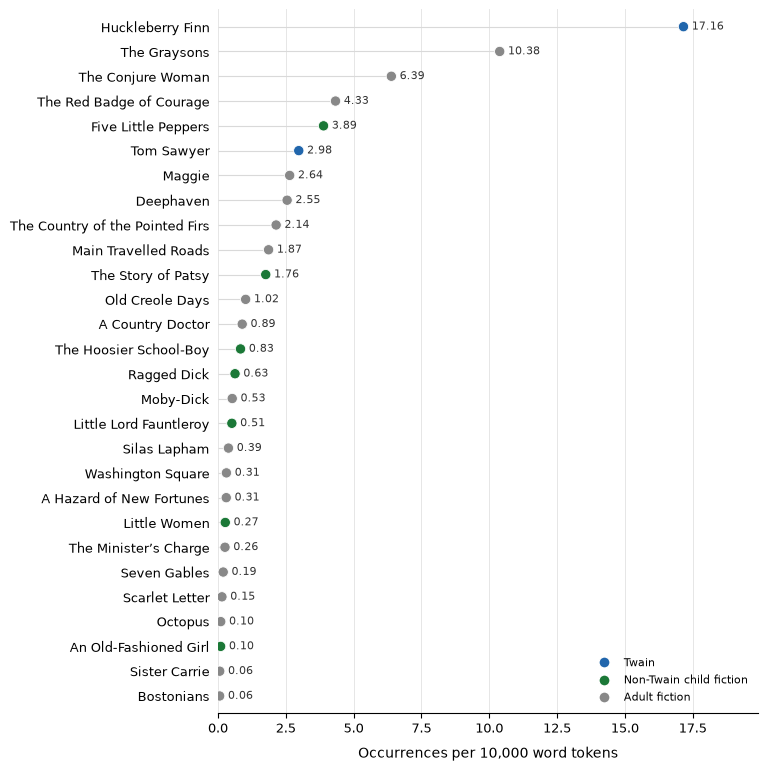

Number of novels plotted: 28
Figures saved in: /Users/manalaltammami/Desktop/twain_child_corpus/figures
PDF filename: Figure_3_a_prefixing_dotplot_20261103_222051_240577.pdf
PNG filename: Figure_3_a_prefixing_dotplot_20261103_222051_240577.png


In [20]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from pathlib import Path
from datetime import datetime
import numpy as np

# ============================================================
# FIGURE 3: CLEVELAND DOT PLOT OF VERBAL A-PREFIXING
# ============================================================

# Use the results already calculated in the notebook.
plot_data = a_prefix_by_book.loc[
    a_prefix_by_book["A-prefixing count"] > 0
].copy()

# Prepare novel titles.
plot_data["Title"] = (
    plot_data["File"]
    .str.replace("_narrative.txt", "", regex=False)
    .str.replace("_", " ", regex=False)
)

# Standardize titles.
plot_data["Title"] = plot_data["Title"].replace({
    "Ministers Charge": "The Minister’s Charge",
    "Hazard New Fortunes": "A Hazard of New Fortunes",
    "Pointed Firs": "The Country of the Pointed Firs",
    "Country Doctor": "A Country Doctor",
    "Graysons": "The Graysons",
    "Conjure Woman": "The Conjure Woman",
    "Red Badge of Courage": "The Red Badge of Courage",
    "An Old Fashioned Girl": "An Old-Fashioned Girl",
    "Hoosier Schoolboy": "The Hoosier School-Boy",
    "Moby Dick": "Moby-Dick",
})

# Sort ascending so the highest rate appears at the top.
plot_data = plot_data.sort_values(
    "Per 10,000",
    ascending=True
).reset_index(drop=True)

# Preserve original corpus colors.
colors = {
    "Twain": "#2166AC",
    "Child": "#1B7837",
    "Adult": "#888888",
}

# Check for unexpected corpus labels.
unknown = set(plot_data["Corpus"]) - set(colors)

if unknown:
    raise ValueError(
        f"Unrecognized corpus categories: {unknown}"
    )

# ============================================================
# FIGURE SETTINGS
# ============================================================

# Compact layout with sufficient height for 28 titles.
fig, ax = plt.subplots(figsize=(9, 8))

y_positions = np.arange(len(plot_data))

rates = plot_data["Per 10,000"].to_numpy()

point_colors = (
    plot_data["Corpus"]
    .map(colors)
    .tolist()
)

# Light horizontal guides for reading across rows.
ax.hlines(
    y=y_positions,
    xmin=0,
    xmax=rates,
    color="#D9D9D9",
    linewidth=0.8,
    zorder=1
)

# Cleveland dot plot.
ax.scatter(
    rates,
    y_positions,
    c=point_colors,
    s=55,
    edgecolors="white",
    linewidths=0.6,
    zorder=3
)

# ============================================================
# NUMERICAL LABELS
# ============================================================

for y, rate in zip(y_positions, rates):
    ax.annotate(
        f"{rate:.2f}",
        xy=(rate, y),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        ha="left",
        fontsize=8,
        color="#333333"
    )

# ============================================================
# NOVEL TITLES
# ============================================================

ax.set_yticks(y_positions)

ax.set_yticklabels(
    plot_data["Title"],
    fontsize=9
)

ax.tick_params(
    axis="y",
    length=0,
    pad=6
)

ax.tick_params(
    axis="x",
    labelsize=9
)

# ============================================================
# AXES AND GRID
# ============================================================

ax.set_xlabel(
    "Occurrences per 10,000 word tokens",
    fontsize=10,
    labelpad=8
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    plot_data["Per 10,000"].max() * 1.16
)

ax.set_ylim(
    -0.7,
    len(plot_data) - 0.3
)

ax.grid(
    axis="x",
    color="#E6E6E6",
    linewidth=0.7
)

ax.set_axisbelow(True)

# Remove unnecessary borders.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

# ============================================================
# LEGEND
# ============================================================

legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=colors["Twain"],
        markeredgecolor="white",
        markersize=8,
        label="Twain"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=colors["Child"],
        markeredgecolor="white",
        markersize=8,
        label="Non-Twain child fiction"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=colors["Adult"],
        markeredgecolor="white",
        markersize=8,
        label="Adult fiction"
    ),
]

ax.legend(
    handles=legend_items,
    loc="lower right",
    fontsize=8,
    frameon=False
)

# Reserve space for long titles.
fig.subplots_adjust(
    left=0.37,
    right=0.97,
    bottom=0.10,
    top=0.98
)

# ============================================================
# SAVE FIGURE
# ============================================================

figure_folder = Path(
    "/Users/manalaltammami/Desktop/twain_child_corpus/figures"
)

figure_folder.mkdir(
    parents=True,
    exist_ok=True
)

timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

filename = f"Figure_3_a_prefixing_dotplot_{timestamp}"

# High-resolution PNG.
fig.savefig(
    figure_folder / f"{filename}.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Vector PDF for Overleaf.
fig.savefig(
    figure_folder / f"{filename}.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Number of novels plotted: {len(plot_data)}")
print(f"Figures saved in: {figure_folder}")
print(f"PDF filename: {filename}.pdf")
print(f"PNG filename: {filename}.png")
